### 1. KONFIGURASI UTAMA

In [1]:
# ============================================================
# 1. KONFIGURASI UTAMA — SESUAIKAN PATH JIKA DIPERLUKAN
# ============================================================
from pathlib import Path

PROJECT_ROOT = Path.cwd()
FEATURES_PATH = PROJECT_ROOT / "features.py"
DATASET_PATH = PROJECT_ROOT.parent / "dataset" / "shami_preprocessed_dataset_raw.csv"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

KOMPOSISI = "token_exclusivity_error_analysis"
SAVE_DIR = ARTIFACTS_DIR / "output"
KOMPOSISI_DIR = ARTIFACTS_DIR / KOMPOSISI
MODEL_DIR = KOMPOSISI_DIR / "model"
IMAGE_DIR = KOMPOSISI_DIR / "image"
DOCS_DIR = KOMPOSISI_DIR / "docs"

for directory in [SAVE_DIR, KOMPOSISI_DIR, MODEL_DIR, IMAGE_DIR, DOCS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# "test"  = analisis eksploratif pascahoc menggunakan y_true test set.
# "train" = penanda leksikal ditentukan dari sub-train asli.
REFERENCE_SOURCE = "test"

TOP_N_TOKEN = 10
MIN_FREQ = 5
RATIO_THRESHOLD = 3.0
MIN_N_MAIN = 10
MIN_N_EXPLORATORY = 5

RANDOM_STATE = 42

print("Project root     :", PROJECT_ROOT)
print("Dataset          :", DATASET_PATH)
print("Artifacts        :", ARTIFACTS_DIR)
print("Reference source :", REFERENCE_SOURCE)

Project root     : /Users/moel_04/Library/CloudStorage/GoogleDrive-maulanaihsanpress@gmail.com/My Drive/tesisugm/research
Dataset          : /Users/moel_04/Library/CloudStorage/GoogleDrive-maulanaihsanpress@gmail.com/My Drive/tesisugm/dataset/shami_preprocessed_dataset_raw.csv
Artifacts        : /Users/moel_04/Library/CloudStorage/GoogleDrive-maulanaihsanpress@gmail.com/My Drive/tesisugm/research/artifacts
Reference source : test


### 2. IMPORT LIBRARY DAN SHAMI EXTRACTOR

In [2]:
import gc
import hashlib
import importlib.util
import os
import re
import sys
import warnings
from collections import Counter, defaultdict

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.sparse import csr_matrix, issparse
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

if not FEATURES_PATH.exists():
    raise FileNotFoundError(
        f"features.py tidak ditemukan: {FEATURES_PATH}\n"
        "Ubah FEATURES_PATH pada cell konfigurasi."
    )

spec = importlib.util.spec_from_file_location("features", FEATURES_PATH)
features = importlib.util.module_from_spec(spec)
sys.modules["features"] = features
spec.loader.exec_module(features)

from features import ShamiFeatureExtractor, clean_noise, clean_char

print("Features file   :", features.__file__)
print("Features version:", getattr(features, "FEATURES_VERSION", "unknown"))

Features file   : /Users/moel_04/Library/CloudStorage/GoogleDrive-maulanaihsanpress@gmail.com/My Drive/tesisugm/research/features.py
Features version: Shami Extractor


### 3. LABEL DAN SKENARIO KANONIS

In [3]:
DIALECT_MAP = {
    "Jordan": "Yordania",
    "Yordania": "Yordania",
    "Lebanon": "Lebanon",
    "Palestine": "Palestina",
    "Palestina": "Palestina",
    "Syria": "Suriah",
    "Suriah": "Suriah",
}

SCENARIO_MAP = {
    "original": "original",
    "smote": "smote",
    "knsmote": "astra_smote",
    "astra_smote": "astra_smote",
    "astra-smote": "astra_smote",
    "dbscansmote": "smote_radiant",
    "smote_radiant": "smote_radiant",
    "smote-radiant": "smote_radiant",
    "astra_radiant": "astra_radiant",
    "astra-radiant": "astra_radiant",
    "balanced_weighted": "class_weight",
    "classweight": "class_weight",
    "class_weight": "class_weight",
}

DIALECT_ORDER = ["Yordania", "Lebanon", "Palestina", "Suriah"]
RAW_SCENARIOS = [
    "original",
    "smote",
    "knsmote",
    "dbscansmote",
    "balanced_weighted",
    "astra_radiant",
]
ALGORITHMS = ["lightgbm", "xgboost"]

def canonical_dialect(value):
    value = str(value).strip()
    return DIALECT_MAP.get(value, value)

def canonical_scenario(value):
    value = str(value).strip().lower()
    return SCENARIO_MAP.get(value, value)

def canonical_algorithm(value):
    value = str(value).strip().lower()
    if value in {"lgbm", "light_gbm"}:
        return "lightgbm"
    if value in {"xgb", "xg_boost"}:
        return "xgboost"
    return value

### 4. LOAD DATASET DAN BUAT SPLIT

In [4]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATASET_PATH}\n"
        "Ubah DATASET_PATH pada cell konfigurasi."
    )

df = pd.read_csv(DATASET_PATH)

df = (
    df.dropna(subset=["text", "label"])
      .rename(columns={"label": "country"})
      .copy()
)

# Normalisasi teks satu kali
df["clean_word"] = df["text"].apply(clean_noise)
df["clean_char"] = df["text"].apply(clean_char)

X = df[["text", "clean_word", "clean_char"]]

# WAJIB: gunakan encoder yang sama dengan model/cache
encoder_path = SAVE_DIR / "label_encoder.pkl"

if not encoder_path.exists():
    raise FileNotFoundError(
        f"Label encoder model tidak ditemukan: {encoder_path}"
    )

le = joblib.load(encoder_path)
label_names = np.asarray(le.classes_)

print("Label encoder model:")
for class_id, label in enumerate(label_names):
    print(
        f"  {class_id}: {label} "
        f"→ {canonical_dialect(label)}"
    )

# Mencocokkan label dataset dengan representasi yang dipakai encoder.
# Ini tetap bekerja jika dataset memakai English/Indonesia,
# selama makna dialeknya sama.
encoder_class_by_canonical = {
    canonical_dialect(label): label
    for label in label_names
}

def convert_to_model_label(value):
    canonical = canonical_dialect(value)

    if canonical not in encoder_class_by_canonical:
        raise ValueError(
            f"Label {value!r} ({canonical!r}) "
            "tidak ditemukan dalam label encoder model."
        )

    return encoder_class_by_canonical[canonical]

y_model_label = df["country"].apply(
    convert_to_model_label
)

y_encoded = le.transform(y_model_label)

# Label kanonis hanya untuk pelaporan, bukan untuk encoding model.
df["country_canonical"] = df["country"].apply(
    canonical_dialect
)

# Split harus identik dengan eksperimen asli
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    stratify=y_encoded,
    random_state=RANDOM_STATE,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=RANDOM_STATE,
)

def show_distribution(values, title):
    counts = Counter(np.asarray(values))

    print(f"\n{title}")

    for class_id in sorted(counts):
        raw_name = label_names[int(class_id)]
        canonical_name = canonical_dialect(raw_name)

        print(
            f"  {class_id} "
            f"({raw_name} → {canonical_name:10s}): "
            f"{counts[class_id]:,}"
        )

show_distribution(y_train, "SUB-TRAIN")
show_distribution(y_val, "VALIDATION")
show_distribution(y_test, "TEST")

Label encoder model:
  0: Jordan → Yordania
  1: Lebanon → Lebanon
  2: Palestine → Palestina
  3: Syria → Suriah

SUB-TRAIN
  0 (Jordan → Yordania  ): 4,210
  1 (Lebanon → Lebanon   ): 6,498
  2 (Palestine → Palestina ): 6,385
  3 (Syria → Suriah    ): 22,655

VALIDATION
  0 (Jordan → Yordania  ): 1,053
  1 (Lebanon → Lebanon   ): 1,624
  2 (Palestine → Palestina ): 1,596
  3 (Syria → Suriah    ): 5,664

TEST
  0 (Jordan → Yordania  ): 1,754
  1 (Lebanon → Lebanon   ): 2,707
  2 (Palestine → Palestina ): 2,661
  3 (Syria → Suriah    ): 9,440


### 5. LOAD/BUILD FEATURE EXTRACTOR DAN MATRIX TEST

In [5]:
CHI2_PCT = 0.015
MI_PCT23 = 0.010
MI_PCT45 = 0.015
USE_OOF_INTERACTION = True

base_signature = "Shami Extractor_0890ac2785"
base_cache_dir = PROJECT_ROOT / "cache" / base_signature
base_cache_dir.mkdir(parents=True, exist_ok=True)

feat_cache_key = (
    f"chi2_{CHI2_PCT}_mi23_{MI_PCT23}_mi45_{MI_PCT45}"
    f"_oof_inter_{int(USE_OOF_INTERACTION)}"
)
data_hash = hashlib.md5(df["text"].str.cat().encode()).hexdigest()[:8]
feat_cache_dir = base_cache_dir / feat_cache_key / data_hash
feat_cache_dir.mkdir(parents=True, exist_ok=True)

feat_path = base_cache_dir / "feature_extractor.pkl"

if feat_path.exists():
    print("✅ Loading feature extractor...")
    feat = joblib.load(feat_path)
else:
    print("⚙️ Building feature extractor...")
    feat = ShamiFeatureExtractor(
        chi2_pct=CHI2_PCT,
        mi_pct23=MI_PCT23,
        mi_pct45=MI_PCT45,
        use_oof_lr=True,
        use_oof_interaction=USE_OOF_INTERACTION,
    )
    feat.fit(X_train, y_train)
    joblib.dump(feat, feat_path)

feat.update_chi2_pct(CHI2_PCT)
feat.update_mi_pct(new_pct23=MI_PCT23, new_pct45=MI_PCT45)

xte_path = feat_cache_dir / "Xte_feat.pkl"
yte_path = feat_cache_dir / "y_test.pkl"

if xte_path.exists() and yte_path.exists():
    print("✅ Loading test feature matrix from cache...")
    Xte_sel = joblib.load(xte_path)
    y_test_cached = np.asarray(joblib.load(yte_path))

    current = np.asarray(y_test).reshape(-1)
    cached  = np.asarray(y_test_cached).reshape(-1)

    print("Current shape :", current.shape)
    print("Cached shape  :", cached.shape)
    print("Current dtype :", current.dtype)
    print("Cached dtype  :", cached.dtype)

    if len(current) == len(cached):
        mismatch = current != cached

        print("Jumlah berbeda :", mismatch.sum())
        print("Persentase     :", mismatch.mean() * 100, "%")
        print("Distribusi current:", Counter(current))
        print("Distribusi cached :", Counter(cached))
        print("10 current pertama:", current[:10])
        print("10 cached pertama :", cached[:10])

    if not np.array_equal(np.asarray(y_test), y_test_cached):
        raise AssertionError(
            "y_test cache tidak sama dengan split saat ini. "
            "Hapus cache atau periksa dataset/split."
        )
else:
    print("⚙️ Transforming test set...")
    Xte_sel = feat.transform(X_test, is_train=False)
    joblib.dump(Xte_sel, xte_path)
    joblib.dump(y_test, yte_path)

print("Test feature shape:", Xte_sel.shape)

✅ Loading feature extractor...
[update] chi2_pct=1.50% -> chi2_k=2,420
[update] mi_pct23=1.00% -> mi_k23=500
[update] mi_pct45=1.50% -> mi_k45=2,650
✅ Loading test feature matrix from cache...
Current shape : (16562,)
Cached shape  : (16562,)
Current dtype : int64
Cached dtype  : int64
Jumlah berbeda : 0
Persentase     : 0.0 %
Distribusi current: Counter({np.int64(3): 9440, np.int64(1): 2707, np.int64(2): 2661, np.int64(0): 1754})
Distribusi cached : Counter({np.int64(3): 9440, np.int64(1): 2707, np.int64(2): 2661, np.int64(0): 1754})
10 current pertama: [3 3 3 2 3 3 3 3 0 0]
10 cached pertama : [3 3 3 2 3 3 3 3 0 0]
Test feature shape: (16562, 5644)


### 6. LOAD 12 MODEL (2 ALGORITMA × 6 SKENARIO)

In [6]:
models = {}

for algorithm in ALGORITHMS:
    for raw_scenario in RAW_SCENARIOS:
        model_name = f"model_{algorithm}_{raw_scenario}.pkl"
        model_path = (
            ARTIFACTS_DIR
            / f"{algorithm}_{raw_scenario}"
            / "model"
            / model_name
        )

        if model_path.exists():
            key = f"{algorithm}_{raw_scenario}"
            model = joblib.load(model_path)

            expected_features = getattr(model, "n_features_in_", None)
            if expected_features is not None and expected_features != Xte_sel.shape[1]:
                raise ValueError(
                    f"Dimensi fitur {key} tidak cocok: model={expected_features}, "
                    f"Xte_sel={Xte_sel.shape[1]}"
                )

            models[key] = model
            print(f"✅ Loaded: {key}")
        else:
            print(f"⚠️ Not found: {model_path}")

print(f"\nTotal model loaded: {len(models)}/12")

if not models:
    raise FileNotFoundError("Tidak ada model yang berhasil dimuat.")

✅ Loaded: lightgbm_original
✅ Loaded: lightgbm_smote
✅ Loaded: lightgbm_knsmote
✅ Loaded: lightgbm_dbscansmote
✅ Loaded: lightgbm_balanced_weighted
✅ Loaded: lightgbm_astra_radiant
✅ Loaded: xgboost_original
✅ Loaded: xgboost_smote
✅ Loaded: xgboost_knsmote
✅ Loaded: xgboost_dbscansmote
✅ Loaded: xgboost_balanced_weighted
✅ Loaded: xgboost_astra_radiant

Total model loaded: 12/12


### 7. PREDIKSI DAN DATAFRAME ERROR ANALYSIS

In [7]:
def build_df_export(model, algorithm, scenario, X_matrix, X_raw, y_true, labels):
    algorithm = canonical_algorithm(algorithm)
    scenario = canonical_scenario(scenario)

    raw_labels = np.asarray(labels)
    canonical_labels = np.asarray([canonical_dialect(x) for x in raw_labels])

    if algorithm == "xgboost" and issparse(X_matrix):
        X_input = csr_matrix(X_matrix, dtype=np.float32)
    else:
        X_input = X_matrix

    if algorithm == "lightgbm":
        best_iteration = getattr(model, "best_iteration_", None)
        if best_iteration is not None and best_iteration > 0:
            probabilities = model.predict_proba(
                X_input, num_iteration=best_iteration
            )
            predictions = model.predict(
                X_input, num_iteration=best_iteration
            ).astype(int)
        else:
            probabilities = model.predict_proba(X_input)
            predictions = model.predict(X_input).astype(int)
    else:
        probabilities = model.predict_proba(X_input)
        predictions = model.predict(X_input).astype(int)

    y_true = np.asarray(y_true).astype(int)
    true_labels = canonical_labels[y_true]
    predicted_labels = canonical_labels[predictions]
    label_index = {name: list(canonical_labels).index(name) for name in DIALECT_ORDER}
    sorted_probabilities = np.sort(probabilities, axis=1)

    result = pd.DataFrame({
        "sample_id": X_raw.index.astype(str).values,
        "text": X_raw["text"].fillna("").astype(str).values,
        "clean_word": X_raw["clean_word"].fillna("").astype(str).values,
        "true_label": true_labels,
        "pred_label": predicted_labels,
        "correct": y_true == predictions,
        "confidence": np.max(probabilities, axis=1),
        "conf_yordania": probabilities[:, label_index["Yordania"]],
        "conf_lebanon": probabilities[:, label_index["Lebanon"]],
        "conf_palestina": probabilities[:, label_index["Palestina"]],
        "conf_suriah": probabilities[:, label_index["Suriah"]],
        "entropy": (-probabilities * np.log(probabilities + 1e-12)).sum(axis=1),
        "margin": sorted_probabilities[:, -1] - sorted_probabilities[:, -2],
        "algorithm": algorithm,
        "scenario": scenario,
    })

    return result

### 8. MEMBANGUN TOKEN REFERENCE

In [8]:
def prepare_reference_dataframe(X_raw, y_reference, labels):
    y_reference = np.asarray(y_reference)

    if np.issubdtype(y_reference.dtype, np.integer):
        true_labels = [
            canonical_dialect(labels[int(i)]) for i in y_reference
        ]
    else:
        true_labels = [canonical_dialect(i) for i in y_reference]

    return pd.DataFrame({
        "text": X_raw["text"].fillna("").astype(str).values,
        "clean_word": X_raw["clean_word"].fillna("").astype(str).values,
        "true_label": true_labels,
    })


def build_surface_form_map(df_reference):
    """Memetakan token ternormalisasi ke bentuk permukaan yang paling sering."""
    surface_forms = defaultdict(Counter)

    for raw_text in df_reference["text"]:
        for surface in re.findall(r"[\u0600-\u06FF]+", str(raw_text)):
            normalized_parts = str(clean_noise(surface)).split()
            for normalized in normalized_parts:
                if normalized:
                    surface_forms[normalized][surface] += 1

    return {
        normalized: counts.most_common(1)[0][0]
        for normalized, counts in surface_forms.items()
        if counts
    }


def build_token_reference(
    df_reference,
    reference_source="test",
    top_n=10,
    min_freq=5,
    ratio_threshold=3.0,
):
    rows = []
    surface_map = build_surface_form_map(df_reference)

    for dialect in DIALECT_ORDER:
        source = df_reference[df_reference["true_label"] == dialect]
        others = df_reference[df_reference["true_label"] != dialect]

        source_counter = Counter()
        others_counter = Counter()

        for text in source["clean_word"]:
            source_counter.update(str(text).split())

        for text in others["clean_word"]:
            others_counter.update(str(text).split())

        n_source_documents = len(source)
        n_other_documents = len(others)
        candidates = []

        for token, freq_source in source_counter.items():
            if freq_source < min_freq or len(token) < 2:
                continue

            freq_others = others_counter.get(token, 0)
            source_rate = freq_source / max(n_source_documents, 1)
            others_rate = freq_others / max(n_other_documents, 1)
            exclusivity = source_rate / (others_rate + 1e-6)

            if exclusivity < ratio_threshold:
                continue

            candidates.append({
                "dialect": dialect,
                "token": token,
                "token_display": surface_map.get(token, token),
                "freq_src_reference": int(freq_source),
                "freq_others_reference": int(freq_others),
                "exclusivity": float(exclusivity),
                "reference_source": reference_source,
            })

        # Tidak melibatkan collapse_rate atau keluaran model.
        candidates.sort(
            key=lambda item: (
                -item["exclusivity"],
                -item["freq_src_reference"],
                item["token"],
            )
        )

        for rank, candidate in enumerate(candidates[:top_n], start=1):
            candidate["token_rank"] = rank
            rows.append(candidate)

    reference = pd.DataFrame(rows)

    if reference.empty:
        raise ValueError("Tidak ada token yang memenuhi kriteria referensi.")

    return reference

### 9. EVALUASI TOKEN TERKUNCI DAN WILSON INTERVAL

In [9]:
def wilson_interval(wrong_count, n_samples, z=1.96):
    if n_samples == 0:
        return np.nan, np.nan

    proportion = wrong_count / n_samples
    denominator = 1 + z**2 / n_samples
    centre = (proportion + z**2 / (2 * n_samples)) / denominator
    half_width = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / n_samples
            + z**2 / (4 * n_samples**2)
        )
        / denominator
    )
    return max(0, centre - half_width), min(1, centre + half_width)


def evaluate_locked_tokens(df_export, token_reference, algorithm, scenario):
    token_sets = df_export["clean_word"].apply(
        lambda text: set(str(text).split())
    )
    rows = []

    for ref in token_reference.itertuples(index=False):
        mask = (
            (df_export["true_label"] == ref.dialect)
            & token_sets.apply(lambda tokens: ref.token in tokens)
        )
        observations = df_export.loc[mask]

        n_samples = len(observations)
        correct_count = int(observations["correct"].sum())
        wrong_count = int(n_samples - correct_count)

        collapse_rate = wrong_count / n_samples if n_samples else np.nan
        average_confidence = (
            float(observations["confidence"].mean()) if n_samples else np.nan
        )
        ci_low, ci_high = wilson_interval(wrong_count, n_samples)

        wrong_predictions = (
            observations.loc[~observations["correct"], "pred_label"]
            .value_counts()
        )
        top_wrong_prediction = (
            wrong_predictions.index[0] if len(wrong_predictions) else "-"
        )

        if n_samples >= MIN_N_MAIN:
            evidence_level = "main"
        elif n_samples >= MIN_N_EXPLORATORY:
            evidence_level = "exploratory"
        else:
            evidence_level = "insufficient"

        rows.append({
            "algorithm": canonical_algorithm(algorithm),
            "scenario": canonical_scenario(scenario),
            "dialect": ref.dialect,
            "token": ref.token,
            "token_display": ref.token_display,
            "token_rank": ref.token_rank,
            "reference_source": ref.reference_source,
            "freq_src_reference": ref.freq_src_reference,
            "freq_others_reference": ref.freq_others_reference,
            "exclusivity": ref.exclusivity,
            "n_samples_test": n_samples,
            "correct_count": correct_count,
            "wrong_count": wrong_count,
            "collapse_rate": collapse_rate,
            "collapse_ci_low": ci_low,
            "collapse_ci_high": ci_high,
            "avg_confidence": average_confidence,
            "top_wrong_pred": top_wrong_prediction,
            "evidence_level": evidence_level,
        })

    return pd.DataFrame(rows)

### 10. PEMERIKSAAN KONSISTENSI

In [10]:
def validate_standardized_data(token_results, token_reference):
    unique_key = ["algorithm", "scenario", "dialect", "token"]
    duplicate_count = token_results.duplicated(subset=unique_key).sum()
    if duplicate_count:
        raise AssertionError(f"Ditemukan {duplicate_count} kunci duplikat.")

    invariant_columns = [
        "freq_src_reference",
        "freq_others_reference",
        "exclusivity",
    ]
    invariant_check = (
        token_results
        .groupby(["dialect", "token"])[invariant_columns]
        .nunique(dropna=False)
    )
    if (invariant_check > 1).any().any():
        raise AssertionError("Frekuensi atau eksklusivitas berubah antar-model.")

    n_test_check = (
        token_results
        .groupby(["dialect", "token"])["n_samples_test"]
        .nunique(dropna=False)
    )
    if (n_test_check > 1).any():
        raise AssertionError(
            "n_samples_test berubah antar-model untuk token yang sama:\n"
            + n_test_check[n_test_check > 1].to_string()
        )

    reference_set = set(zip(token_reference["dialect"], token_reference["token"]))
    for key, group in token_results.groupby(["algorithm", "scenario"]):
        observed_set = set(zip(group["dialect"], group["token"]))
        if observed_set != reference_set:
            raise AssertionError(f"Daftar token tidak identik pada {key}.")

    print("✅ Tidak ada kunci duplikat.")
    print("✅ Daftar token identik pada seluruh model dan skenario.")
    print("✅ Frekuensi dan eksklusivitas invariant.")
    print("✅ n_samples_test identik pada seluruh model dan skenario.")

### 11. JALANKAN ANALISIS DAN EKSPOR CSV

In [11]:
if REFERENCE_SOURCE == "test":
    df_reference = prepare_reference_dataframe(X_test, y_test, label_names)
elif REFERENCE_SOURCE == "train":
    df_reference = prepare_reference_dataframe(X_train, y_train, label_names)
else:
    raise ValueError("REFERENCE_SOURCE harus 'test' atau 'train'.")

token_reference = build_token_reference(
    df_reference=df_reference,
    reference_source=REFERENCE_SOURCE,
    top_n=TOP_N_TOKEN,
    min_freq=MIN_FREQ,
    ratio_threshold=RATIO_THRESHOLD,
)

token_reference.to_csv(
    DOCS_DIR / "token_reference.csv",
    index=False,
    encoding="utf-8-sig",
)

all_exports = []
all_token_results = []

for key, model in models.items():
    algorithm_raw, scenario_raw = key.split("_", 1)
    algorithm = canonical_algorithm(algorithm_raw)
    scenario = canonical_scenario(scenario_raw)

    print(f"▶ {algorithm} × {scenario}")

    export = build_df_export(
        model=model,
        algorithm=algorithm,
        scenario=scenario,
        X_matrix=Xte_sel,
        X_raw=X_test,
        y_true=y_test,
        labels=label_names,
    )
    all_exports.append(export)

    token_result = evaluate_locked_tokens(
        df_export=export,
        token_reference=token_reference,
        algorithm=algorithm,
        scenario=scenario,
    )
    all_token_results.append(token_result)

    export.to_csv(
        DOCS_DIR / f"{algorithm}_{scenario}_error_analysis_full.csv",
        index=False,
        encoding="utf-8-sig",
    )
    token_result.to_csv(
        DOCS_DIR / f"{algorithm}_{scenario}_token_behavior.csv",
        index=False,
        encoding="utf-8-sig",
    )

df_combined = pd.concat(all_exports, ignore_index=True)
df_token_standardized = pd.concat(all_token_results, ignore_index=True)

df_combined.to_csv(
    DOCS_DIR / "ALL_error_analysis_combined.csv",
    index=False,
    encoding="utf-8-sig",
)
df_token_standardized.to_csv(
    DOCS_DIR / "ALL_token_exclusivity_standardized.csv",
    index=False,
    encoding="utf-8-sig",
)

validate_standardized_data(df_token_standardized, token_reference)

print("\nToken reference:", len(token_reference))
print("Standardized rows:", len(df_token_standardized))
display(token_reference)

▶ lightgbm × original
▶ lightgbm × smote
▶ lightgbm × astra_smote
▶ lightgbm × smote_radiant
▶ lightgbm × class_weight
▶ lightgbm × astra_radiant
▶ xgboost × original
▶ xgboost × smote
▶ xgboost × astra_smote
▶ xgboost × smote_radiant
▶ xgboost × class_weight
▶ xgboost × astra_radiant
✅ Tidak ada kunci duplikat.
✅ Daftar token identik pada seluruh model dan skenario.
✅ Frekuensi dan eksklusivitas invariant.
✅ n_samples_test identik pada seluruh model dan skenario.

Token reference: 40
Standardized rows: 480


,dialect,token,token_display,freq_src_reference,freq_others_reference,exclusivity,reference_source,token_rank
0,Yordania,يزم,يزم,10,0,5701.254276,test,1
1,Yordania,وانتا,وانتا,9,0,5131.128848,test,2
2,Yordania,اصير,اصير,8,0,4561.003421,test,3
3,Yordania,عالفيسبوك,عالفيسبوك,8,0,4561.003421,test,4
4,Yordania,البلوزه,البلوزه,7,0,3990.877993,test,5
5,Yordania,حكتلها,حكتلها,7,0,3990.877993,test,6
6,Yordania,فطبل,فطبل,7,0,3990.877993,test,7
7,Yordania,مجدي,مجدي,7,0,3990.877993,test,8
8,Yordania,نعمان,نعمان,7,0,3990.877993,test,9
9,Yordania,لايك,لايك,6,0,3420.752566,test,10


### 12. EKSPOR TABEL UTAMA, EKSPLORATIF, DAN INSUFFICIENT

In [12]:
df_token_main = df_token_standardized[
    df_token_standardized["evidence_level"] == "main"
].copy()

df_token_exploratory = df_token_standardized[
    df_token_standardized["evidence_level"] == "exploratory"
].copy()

df_token_insufficient = df_token_standardized[
    df_token_standardized["evidence_level"] == "insufficient"
].copy()

df_token_main.to_csv(
    DOCS_DIR / "token_exclusivity_main_n_ge_10.csv",
    index=False,
    encoding="utf-8-sig",
)
df_token_exploratory.to_csv(
    DOCS_DIR / "token_exclusivity_exploratory_n_5_to_9.csv",
    index=False,
    encoding="utf-8-sig",
)
df_token_insufficient.to_csv(
    DOCS_DIR / "token_exclusivity_insufficient_n_lt_5.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Main rows        :", len(df_token_main))
print("Exploratory rows :", len(df_token_exploratory))
print("Insufficient rows:", len(df_token_insufficient))

Main rows        : 348
Exploratory rows : 108
Insufficient rows: 24


### 13. HEATMAP ENAM KOMBINASI REPRESENTATIF

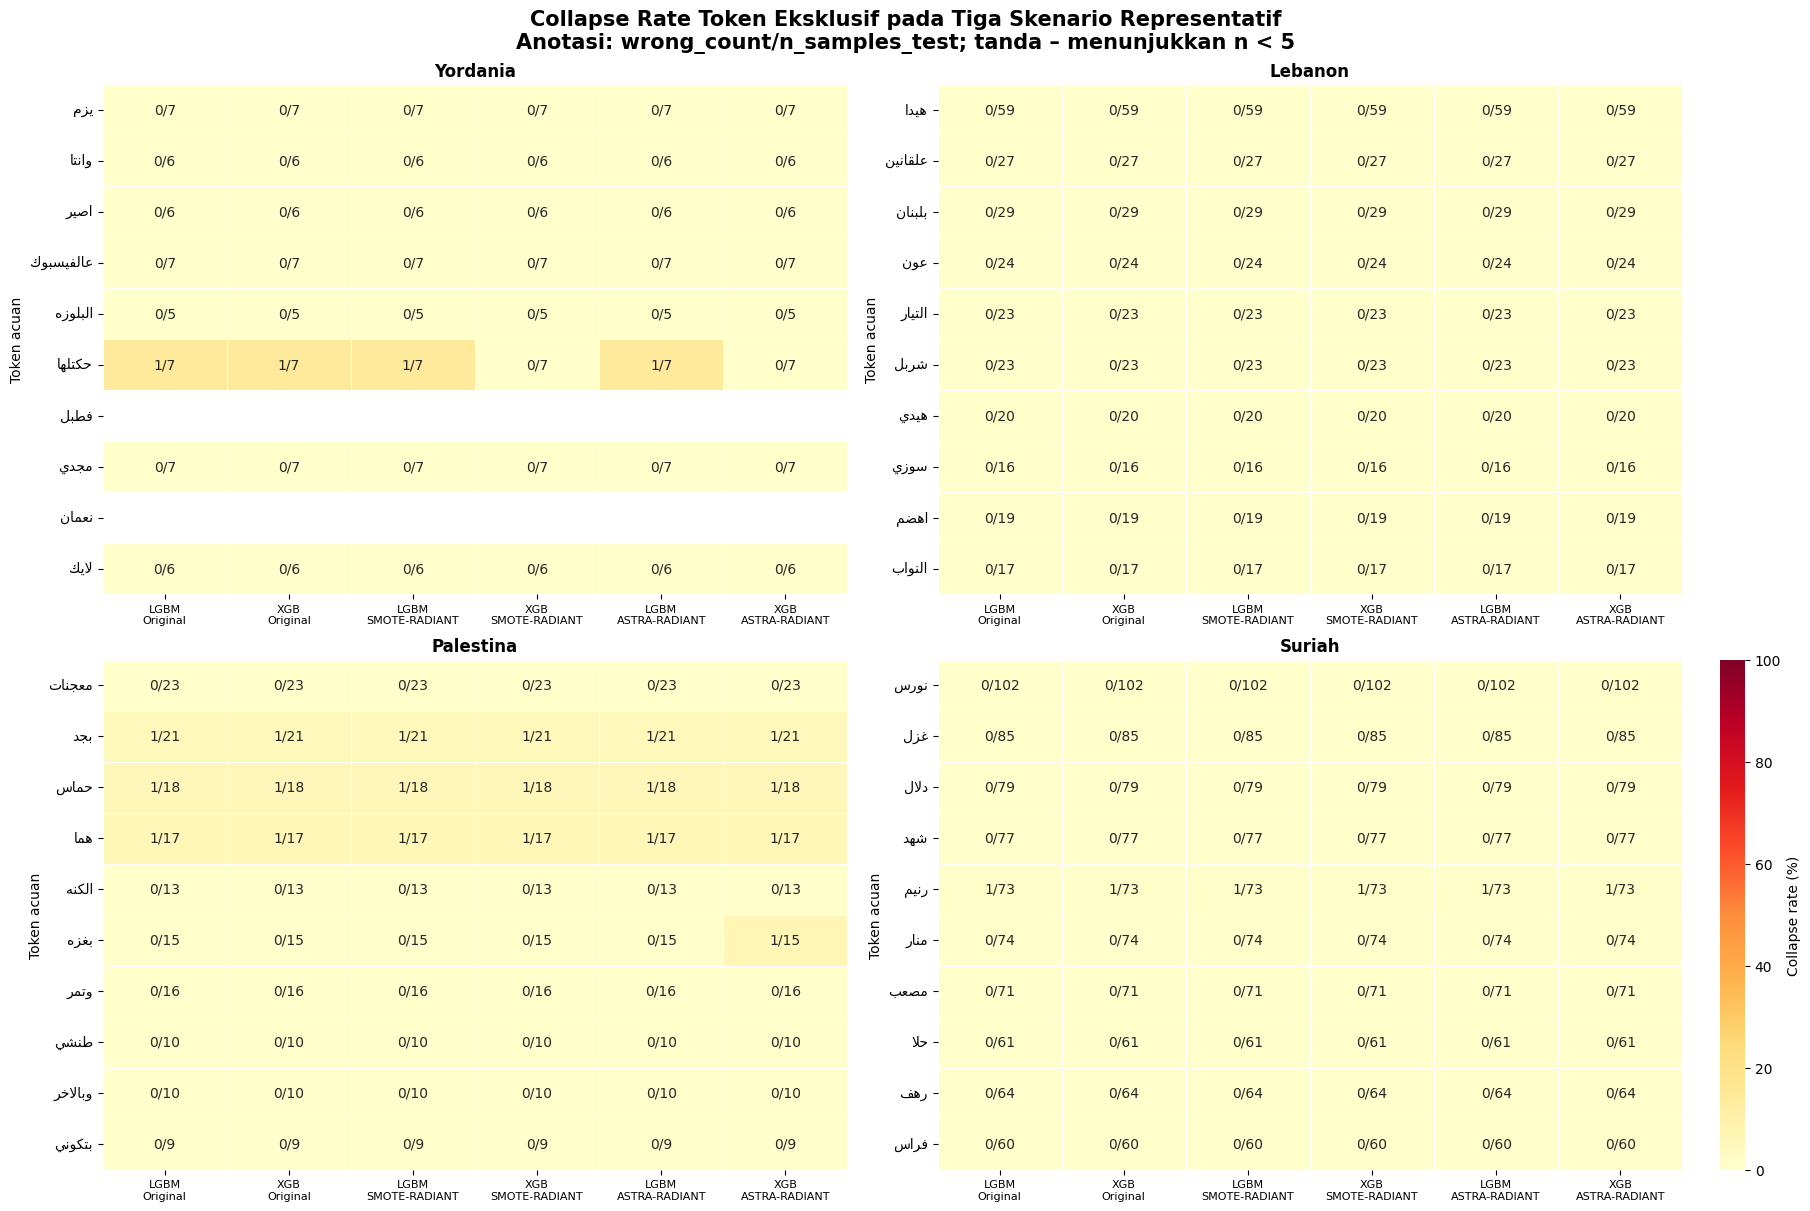

Saved: /Users/moel_04/Library/CloudStorage/GoogleDrive-maulanaihsanpress@gmail.com/My Drive/tesisugm/research/artifacts/token_exclusivity_error_analysis/image/standardized_token_collapse_heatmap.png


In [13]:
try:
    import arabic_reshaper
    from bidi.algorithm import get_display

    def display_arabic(text):
        return get_display(arabic_reshaper.reshape(str(text)))
except ImportError:
    def display_arabic(text):
        return str(text)


REPRESENTATIVE_COLUMNS = [
    ("lightgbm", "original", "LGBM\nOriginal"),
    ("xgboost", "original", "XGB\nOriginal"),
    ("lightgbm", "smote_radiant", "LGBM\nSMOTE-RADIANT"),
    ("xgboost", "smote_radiant", "XGB\nSMOTE-RADIANT"),
    ("lightgbm", "astra_radiant", "LGBM\nASTRA-RADIANT"),
    ("xgboost", "astra_radiant", "XGB\nASTRA-RADIANT"),
]


def plot_standardized_heatmap(token_results, output_path, min_n=5):
    representative = token_results[
        token_results.apply(
            lambda row: (row["algorithm"], row["scenario"])
            in {(a, s) for a, s, _ in REPRESENTATIVE_COLUMNS},
            axis=1,
        )
    ].copy()

    available = set(zip(representative["algorithm"], representative["scenario"]))
    required = {(a, s) for a, s, _ in REPRESENTATIVE_COLUMNS}
    missing = required - available
    if missing:
        print("⚠️ Panel heatmap tidak lengkap karena model tidak tersedia:", missing)

    fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
    axes = axes.flatten()

    for ax, dialect in zip(axes, DIALECT_ORDER):
        subset = representative[representative["dialect"] == dialect].copy()
        subset["model_scenario"] = list(zip(subset["algorithm"], subset["scenario"]))

        reference_order = (
            subset[["token", "token_display", "token_rank"]]
            .drop_duplicates()
            .sort_values("token_rank")
        )
        tokens = reference_order["token"].tolist()
        token_labels = [display_arabic(x) for x in reference_order["token_display"]]

        values = pd.DataFrame(index=tokens)
        annotations = pd.DataFrame(index=tokens)

        for algorithm, scenario, pretty_label in REPRESENTATIVE_COLUMNS:
            block = subset[
                (subset["algorithm"] == algorithm)
                & (subset["scenario"] == scenario)
            ].set_index("token")

            values[pretty_label] = block.reindex(tokens)["collapse_rate"] * 100
            annotations[pretty_label] = block.reindex(tokens).apply(
                lambda row: (
                    f"{int(row['wrong_count'])}/{int(row['n_samples_test'])}"
                    if pd.notna(row.get("n_samples_test"))
                    and row["n_samples_test"] >= min_n
                    else "–"
                ),
                axis=1,
            )

            low_n_mask = block.reindex(tokens)["n_samples_test"] < min_n
            values.loc[low_n_mask.fillna(True), pretty_label] = np.nan

        sns.heatmap(
            values,
            annot=annotations,
            fmt="",
            cmap="YlOrRd",
            vmin=0,
            vmax=100,
            linewidths=0.7,
            linecolor="white",
            cbar=ax is axes[-1],
            cbar_kws={"label": "Collapse rate (%)"},
            ax=ax,
        )

        ax.set_title(dialect, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Token acuan")
        ax.set_yticklabels(token_labels, rotation=0)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=8)

    fig.suptitle(
        "Collapse Rate Token Eksklusif pada Tiga Skenario Representatif\n"
        "Anotasi: wrong_count/n_samples_test; tanda – menunjukkan n < 5",
        fontsize=15,
        fontweight="bold",
    )

    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


HEATMAP_PATH = IMAGE_DIR / "standardized_token_collapse_heatmap.png"
plot_standardized_heatmap(
    df_token_standardized,
    HEATMAP_PATH,
    min_n=MIN_N_EXPLORATORY,
)
print("Saved:", HEATMAP_PATH)

### 14. TABEL VERSI RINGKAS

In [14]:
representative_pairs = {
    ("lightgbm", "original"),
    ("xgboost", "original"),
    ("lightgbm", "smote_radiant"),
    ("xgboost", "smote_radiant"),
    ("lightgbm", "astra_radiant"),
    ("xgboost", "astra_radiant"),
}

df_representative = df_token_standardized[
    df_token_standardized.apply(
        lambda row: (row["algorithm"], row["scenario"]) in representative_pairs,
        axis=1,
    )
].copy()

df_representative["collapse_display"] = df_representative.apply(
    lambda row: (
        f"{row['wrong_count']}/{row['n_samples_test']} "
        f"({row['collapse_rate'] * 100:.1f}%)"
        if row["n_samples_test"] > 0
        else "NA"
    ),
    axis=1,
)

thesis_table = df_representative[
    df_representative["n_samples_test"] >= MIN_N_MAIN
][[
    "dialect",
    "token_display",
    "exclusivity",
    "algorithm",
    "scenario",
    "collapse_display",
    "avg_confidence",
    "top_wrong_pred",
]].sort_values(["dialect", "token_display", "scenario", "algorithm"])

thesis_table.to_csv(
    DOCS_DIR / "token_exclusivity_representative_thesis_table.csv",
    index=False,
    encoding="utf-8-sig",
)

display(thesis_table.head(30))

,dialect,token_display,exclusivity,algorithm,scenario,collapse_display,avg_confidence,top_wrong_pred
214,Lebanon,التيار,8865.903214,lightgbm,astra_radiant,0/23 (0.0%),0.995255,-
454,Lebanon,التيار,8865.903214,xgboost,astra_radiant,0/23 (0.0%),0.994317,-
14,Lebanon,التيار,8865.903214,lightgbm,original,0/23 (0.0%),0.994191,-
254,Lebanon,التيار,8865.903214,xgboost,original,0/23 (0.0%),0.992348,-
134,Lebanon,التيار,8865.903214,lightgbm,smote_radiant,0/23 (0.0%),0.995319,-
374,Lebanon,التيار,8865.903214,xgboost,smote_radiant,0/23 (0.0%),0.994779,-
219,Lebanon,النواب,6649.427410,lightgbm,astra_radiant,0/17 (0.0%),0.997384,-
459,Lebanon,النواب,6649.427410,xgboost,astra_radiant,0/17 (0.0%),0.997009,-
19,Lebanon,النواب,6649.427410,lightgbm,original,0/17 (0.0%),0.994466,-
259,Lebanon,النواب,6649.427410,xgboost,original,0/17 (0.0%),0.994049,-
